In [12]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, FixedLocator
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool
import pandas as pd
import pickle
import scipy
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple#, HandlerTupleVertical

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
with open('pickled/mcmc_0.001_32_40000_2024-10-06_21-24-38.pkl', 'rb') as h:
    mcmc_output = pickle.load(h)
#with open('pickled/mcmc_0.001_64_40000_2024-10-07_01-57-30.pkl', 'rb') as h:
#    mcmc_output = pickle.load(h)

In [14]:
#with open('pickled/mcmc_0.001_32_40000_2024-09-04_04-28-57.pkl', 'rb') as k:
#    mcmc_output2 = pickle.load(k)

In [15]:
#mcmc_output2.shape, mcmc_output.shape

In [16]:
mcmc_output_combined = mcmc_output#np.concatenate((mcmc_output, mcmc_output2), axis=0)
mcmc_output_combined.shape
mcmc_output_combined

array([[-29.70421154,  -2.43477438],
       [-36.52087423,  -3.48058207],
       [-29.82063443,  -3.30047183],
       ...,
       [-31.51432543,  -1.01596384],
       [-37.05420492,  -3.30374695],
       [-33.40506915,  -1.60703326]])

(85312, 2)


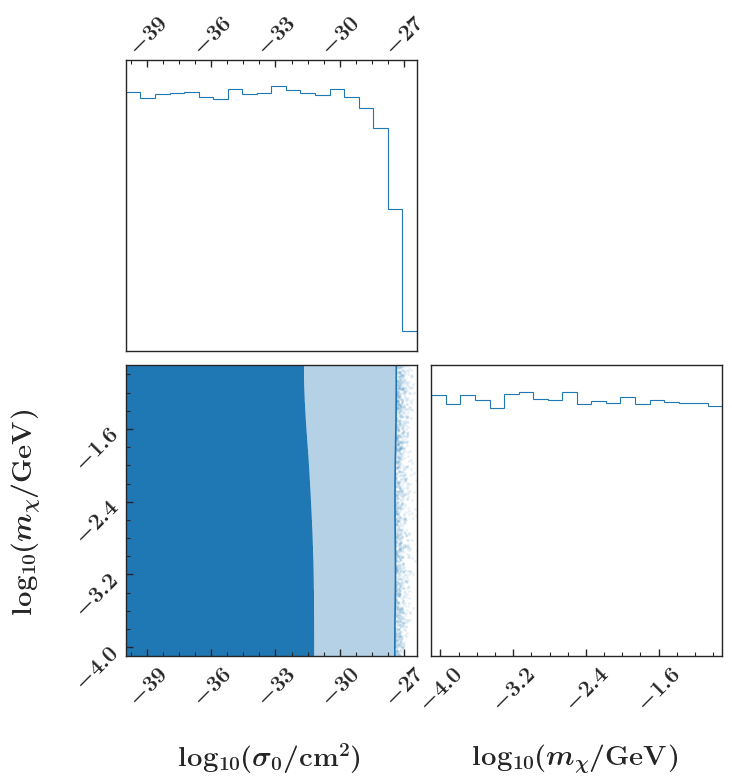

2024-11-02T16:03:45.493961: made plots/corner_plot.png


In [17]:
# create corner plot of results
paper_plot()

print(mcmc_output_combined.shape)
figure = plt.figure(figsize=(8, 8))



labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_combined, 
    labels=labels, 
    dpi=450, 
    smooth=4.5, 
    levels=[0.68, 0.95], 
    top_ticks=True, 
    color='#1f77b4',
    fill_contours=True,
    plot_density=True,
    #contourf_kwargs={"alpha":0.5}, 
    scatter_kws={"alpha": 0}, 
    fig=figure,
    zorder=1
);


# Access the axes of the corner plot
axes = figure.get_axes()

# Enable minor ticks and customize tick parameters for each subplot
for ax in axes:
    ax.minorticks_on()
    ax.tick_params(which='both', direction='in')
    #ax.set_xticks(np.arange(-40, -25, 3))  # Set major ticks for x-axis
    #ax.set_yticks(np.arange(-4, -0.5, 0.5))  # Set major ticks for y-axis
    ax.xaxis.set_zorder(10)  # Higher zorder for x-ticks
    ax.yaxis.set_zorder(10)  # Higher zorder for y-ticks

plt.show()
savefig(fig, 'plots/corner_plot.png', dpi=450)

In [18]:
np.median(mcmc_output_combined[:, 0]), np.median(mcmc_output_combined[:, 1])

(-33.70466064395008, -2.5130386989842783)

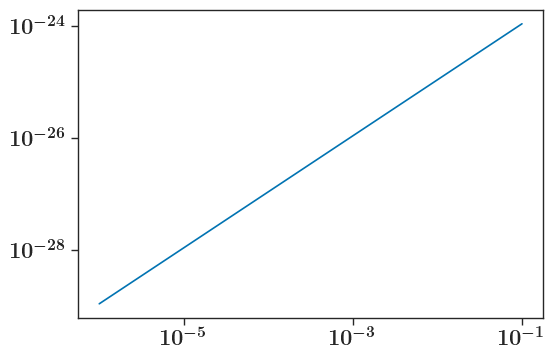

In [19]:
# get prior
# Unpickle the dictionary from the file
with open('data/prior_boundary_points.pkl', 'rb') as f:
    data = pickle.load(f)

# Unpack the dictionary into variables
mchi_values = data['mchi']
s0_max = data['max_s0']

plt.loglog(mchi_values, s0_max)

In [72]:
samples_coords = np.array([[x, y] for y, x in mcmc_output_combined])

# Reshape to get a 2D array of samples
x_samples = samples_coords[:,0]
y_samples = samples_coords[:,1]

# Create a 2D histogram
nbins = 50
H, xedges, yedges = np.histogram2d(x_samples, y_samples, bins=nbins, density=True)

# Apply Gaussian smoothing
sigma = 3.5
H_smooth = scipy.ndimage.gaussian_filter(H, sigma=sigma)

# Compute the bin centers
xcenters = (xedges[:-1] + xedges[1:]) / 2
ycenters = (yedges[:-1] + yedges[1:]) / 2

# Create a meshgrid for the centers
X, Y = np.meshgrid(xcenters, ycenters)

# Flatten the smoothed histogram and sort the values
H_smooth_flat = H_smooth.flatten()
H_smooth_sorted = np.sort(H_smooth_flat)

# Calculate the cumulative distribution function (CDF)
cdf = np.cumsum(H_smooth_sorted)
cdf /= cdf[-1]  # Normalize

# Define the percentiles for contour levels
#percentiles = [50, 75, 90, 95]
#levels = np.percentile(H_smooth_sorted, percentiles)

# Find the 95th percentile value
percentile_value = np.percentile(H_smooth, 5)

# Generate the contour plot
plt.figure(dpi=450)#(figsize=(8, 6))
contour = plt.contour(X, Y, H_smooth.T, levels=[percentile_value],colors='dodgerblue', linewidths=1.5)
#plt.colorbar(contour, label='Density')
#plt.contourf(X, Y, H_smooth.T, levels=[0,percentile_value], alpha=0.5,colors='#1f77b4')


path = contour.collections[0].get_paths()[0]
v = path.vertices
x = v[:,0]
y = v[:,1]

#y2=-24
y2 = np.interp(x, np.log10(mchi_values), np.log10(s0_max),)
plt.fill_between(x, y, y2, where=(y2 >= y), interpolate=True, color='dodgerblue', alpha=0.7,
                 #hatch='//'
                )




# Define each Patch and Line2D
#this_work_patch = mpatches.Patch(facecolor='dodgerblue', alpha=0.5)
#this_work_line = Line2D([0], [0], color='dodgerblue', lw=1.5)

#gluscevic_patch = mpatches.Patch(facecolor='purple', alpha=0.3)
#gluscevic_line = Line2D([0], [0], color='purple', lw=1.5)

#maamari_patch = mpatches.Patch(facecolor='green', alpha=0.3)
#maamari_line = Line2D([0], [0], color='green', lw=1.5)

#excluded_patch = mpatches.Patch(facecolor='black', alpha=1)
#excluded_line = Line2D([0], [0], color='black', lw=1.5, alpha=0)

# Create the handler_map using HandlerTuple for overlapping
handler_map = {
    this_work_line: HandlerLine2D(marker_pad = 0),
    gluscevic_line: HandlerLine2D(marker_pad = 0),
    maamari_line: HandlerLine2D(marker_pad = 0),
    excluded_line: HandlerLine2D(marker_pad = 0)
}

labels = [f'$\mathrm{{This~work}}$', f"$\mathrm{{Gluscevic+ 2018}}$", f"$\mathrm{{Maamari+ 2021}}$", f"$\mathrm{{Excluded~by~prior}}$"]

# Create the legend with overlapping Patch and Line2D
plt.legend(
    [(this_work_patch, this_work_line),
     (gluscevic_patch, gluscevic_line),
     (maamari_patch, maamari_line),
     (excluded_patch, excluded_line)],
    labels=labels,
    handler_map=handler_map,
    loc='lower right',
    frameon=False,
    fontsize=10
)

# prior
plt.plot(np.log10(mchi_values), np.log10(s0_max), color='dodgerblue', linewidth=1.5)
plt.fill_between(
                    np.log10(mchi_values), np.log10(s0_max),
                    y2=1e-26,
                    alpha=0, color='black', 
                    hatch='//', 
                    zorder=15
                )




# load other datasets
maamari = pd.read_csv('data/maamari_2021_constraint.csv', header=None)
plt.plot(np.log10(maamari[0]), np.log10(maamari[1]), label=f"$\mathrm{{Maamari+ 2021}}$", color='gray', linewidth=1.5, linestyle='dotted',)

plt.fill_between(
                    np.log10(maamari[0]), np.log10(maamari[1]),
                    y2=1e-26,
                    alpha=0.2, color='gray',   #hatch='|'
                )


gluscevic = pd.read_csv('data/gluscevic_boddy_2018_velocity_independent.csv', header=None)
plt.plot(np.log10(gluscevic[0]), np.log10(gluscevic[1]), label=f"$\mathrm{{Gluscevic+ 2018}}$", color='gray', lw=1.5, zorder=1, linestyle='dashed')



plt.fill_between(
                    np.log10(gluscevic[0]), np.log10(gluscevic[1]),
                    y2=1e-26,
                    alpha=0.3, color='gray', hatch='x'#linewidth=2
                )



#plt.legend(handles=handles, loc='lower right', frameon=False, fontsize=10, handler_map=handler_map)
#plt.xlabel(r"$m_{\chi} \mathrm{(GeV)}$")
#plt.ylabel(r"$\sigma_0 (\mathrm{cm}^2)$")
#plt.xlabel("DM particle mass (GeV)")
#plt.ylabel(r"Interaction cross section (cm$^2$)")





# Customize the plot
#plt.title('95th Percentile Contour Plot')
plt.xlabel(r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$", size=16)
plt.ylabel(r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", size=16)

# Show the plot
plt.minorticks_on()  # Enable minor ticks
plt.tick_params(which='both', direction='in')

plt.xlim(-4, -1)
plt.ylim(-29, -24)



# Define each Patch and Line2D FOR LEGEND
this_work_patch = mpatches.Patch(facecolor='dodgerblue', alpha=0.6, 
                                 #hatch='//', 
                                 edgecolor='dodgerblue')
this_work_line = Line2D([0], [0], color='dodgerblue', lw=1.5)

gluscevic_patch = mpatches.Patch(facecolor='gray', alpha=0.3, hatch='xx', edgecolor='gray')
gluscevic_line = Line2D([0], [0], color='gray', lw=1.5, linestyle='dashed')

maamari_patch = mpatches.Patch(facecolor='gray', alpha=0.3, edgecolor='gray')
maamari_line = Line2D([0], [0], color='gray', lw=1.5, linestyle='dotted')

excluded_patch = mpatches.Patch(facecolor='black', alpha=0)
excluded_line = Line2D([0], [0], color='black', lw=1.5, alpha=1)


plt.text(-3.5, -25, "CMB T+P")
plt.text(-3.8, -27.5, "MW Satellites")
plt.text(-2, -26.5, 'Galaxy Clusters')

# Create the handler_map using HandlerTuple for overlapping
handler_map = {
    this_work_line: HandlerLine2D(marker_pad = 0),
    gluscevic_line: HandlerLine2D(marker_pad = 0),
    maamari_line: HandlerLine2D(marker_pad = 0),
    excluded_line: HandlerLine2D(marker_pad = 0)
}

# Create the legend with overlapping Patch and Line2D
plt.legend(
    [(this_work_patch, this_work_line),
     (gluscevic_patch, gluscevic_line),
     (maamari_patch, maamari_line),
     #(excluded_patch, excluded_line)
    ],
    ["This work", "Gluscevic+ 2018", "Maamari+ 2021", 
     #"DM-baryon thermalization limit"
    ],
    handler_map=handler_map,
    loc='lower right',
    frameon=False,
    fontsize=10
)
#plt.show()

fig=plt.gcf()
savefig(fig, 'plots/constraints_comparison_entire_space_exclude_region.png', dpi=450)




/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_16564/1337664543.py:82: UserWarning: You have mixed positional and keyword arguments, some input may be discarded.
  plt.legend(


2024-11-08T18:25:38.995596: made plots/constraints_comparison_entire_space_exclude_region.png


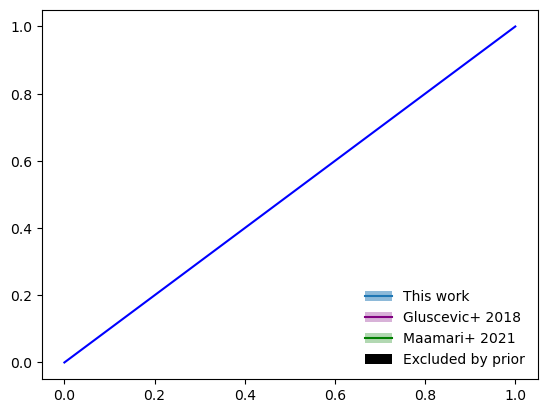

In [8]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
import matplotlib.pyplot as plt

# Example tuple definitions (same as yours)
this_work = (Patch(facecolor='#1f77b4', edgecolor='#1f77b4', alpha=0.5), 
             Line2D([0], [0], color='#1f77b4', lw=1.5))
gluscevic = (Patch(facecolor='purple', edgecolor='purple', alpha=0.3), 
             Line2D([0], [0], color='purple', lw=1.5))
maamari = (Patch(facecolor='green', edgecolor='green', alpha=0.3), 
           Line2D([0], [0], color='green', lw=1.5))
excluded = (Patch(facecolor='black', edgecolor='black', alpha=1), 
            Line2D([0], [0], color='black', lw=1.5))

# Handles list should contain the tuples (groups of Patch and Line2D)
handles = [this_work, gluscevic, maamari, excluded]
labels = [f'$\mathrm{{This~work}}$', f"$\mathrm{{Gluscevic+ 2018}}$", f"$\mathrm{{Maamari+ 2021}}$", f"$\mathrm{{Excluded~by~prior}}$"]

# Create the handler map using the tuple as the key
handler_map = {
    this_work: HandlerTuple(ndivide=None),#HandlerTupleVertical(ndivide=None),
    gluscevic: HandlerTuple(ndivide=None),
    maamari: HandlerTuple(ndivide=None),
    excluded: HandlerTuple(ndivide=None)
}

# Create a simple plot
plt.plot([0, 1], [0, 1], color='blue')


# Define each Patch and Line2D
this_work_patch = mpatches.Patch(facecolor='#1f77b4', alpha=0.5)
this_work_line = Line2D([0], [0], color='#1f77b4', lw=1.5)

gluscevic_patch = mpatches.Patch(facecolor='purple', alpha=0.3)
gluscevic_line = Line2D([0], [0], color='purple', lw=1.5)

maamari_patch = mpatches.Patch(facecolor='green', alpha=0.3)
maamari_line = Line2D([0], [0], color='green', lw=1.5)

excluded_patch = mpatches.Patch(facecolor='black', alpha=1)
excluded_line = Line2D([0], [0], color='black', lw=1.5, alpha=0)

# Create the handler_map using HandlerTuple for overlapping
handler_map = {
    this_work_line: HandlerLine2D(marker_pad = 0),
    gluscevic_line: HandlerLine2D(marker_pad = 0),
    maamari_line: HandlerLine2D(marker_pad = 0),
    excluded_line: HandlerLine2D(marker_pad = 0)
}

# Create the legend with overlapping Patch and Line2D
plt.legend(
    [(this_work_patch, this_work_line),
     (gluscevic_patch, gluscevic_line),
     (maamari_patch, maamari_line),
     (excluded_patch, excluded_line)],
    ["This work", "Gluscevic+ 2018", "Maamari+ 2021", "Excluded by prior"],
    handler_map=handler_map,
    loc='lower right',
    frameon=False,
    fontsize=10
)
# Show the plot (legend will display)
plt.show()


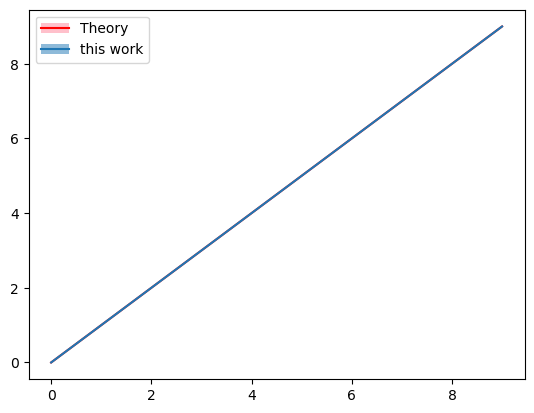

In [5]:
from matplotlib import pyplot as plt 
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerLine2D
import numpy as np

line, = plt.plot(range(10), color = 'red')
patch = mpatches.Patch(facecolor='pink', alpha=1.0, linewidth=0)

this_work_line, = plt.plot(range(10), color = '#1f77b4')
this_work_patch =mpatches.Patch(facecolor='#1f77b4', alpha=0.5)
handler_map = {line : HandlerLine2D(marker_pad = 0), 
              this_work_line: HandlerLine2D(marker_pad = 0)}

plt.legend([(patch, line), (this_work_patch, this_work_line)], ["Theory", "this work"], handler_map =  handler_map)
plt.show()

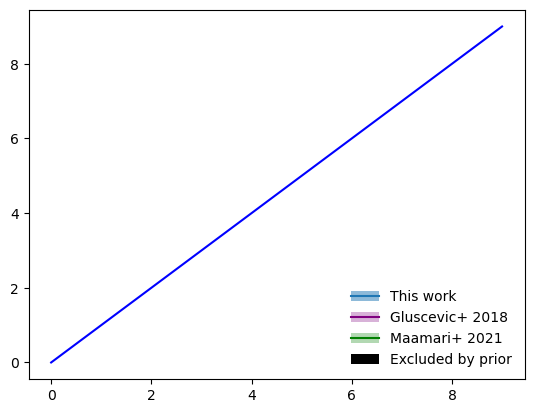

In [6]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
# test legend

# Create plot elements for context (dummy plot)
plt.plot(range(10), color='blue')  # Adding this for context

# Define each Patch and Line2D
this_work_patch = mpatches.Patch(facecolor='#1f77b4', alpha=0.5)
this_work_line = Line2D([0], [0], color='#1f77b4', lw=1.5)

gluscevic_patch = mpatches.Patch(facecolor='purple', alpha=0.3)
gluscevic_line = Line2D([0], [0], color='purple', lw=1.5)

maamari_patch = mpatches.Patch(facecolor='green', alpha=0.3)
maamari_line = Line2D([0], [0], color='green', lw=1.5)

excluded_patch = mpatches.Patch(facecolor='black', alpha=1)
excluded_line = Line2D([0], [0], color='black', lw=1.5, alpha=0)

# Create the handler_map using HandlerTuple for overlapping
handler_map = {
    this_work_line: HandlerLine2D(marker_pad = 0),
    gluscevic_line: HandlerLine2D(marker_pad = 0),
    maamari_line: HandlerLine2D(marker_pad = 0),
    excluded_line: HandlerLine2D(marker_pad = 0)
}

# Create the legend with overlapping Patch and Line2D
plt.legend(
    [(this_work_patch, this_work_line),
     (gluscevic_patch, gluscevic_line),
     (maamari_patch, maamari_line),
     (excluded_patch, excluded_line)],
    ["This work", "Gluscevic+ 2018", "Maamari+ 2021", "Excluded by prior"],
    handler_map=handler_map,
    loc='lower right',
    frameon=False,
    fontsize=10
)

# Show plot with legend
plt.show()


In [7]:
plt.plot(x, y, lw=5)
plt.ylim(-29, -24)
np.mean(y)

NameError: name 'x' is not defined

In [50]:
10**np.mean(y)

9.278787927536872e-28

In [14]:
10**np.mean(y)

9.278787927536872e-28

In [15]:
np.log10(u.MeV.to(u.GeV))

-3.0

In [16]:
np.log10(100*u.keV.to(u.GeV))

-4.0

(21328, 2)


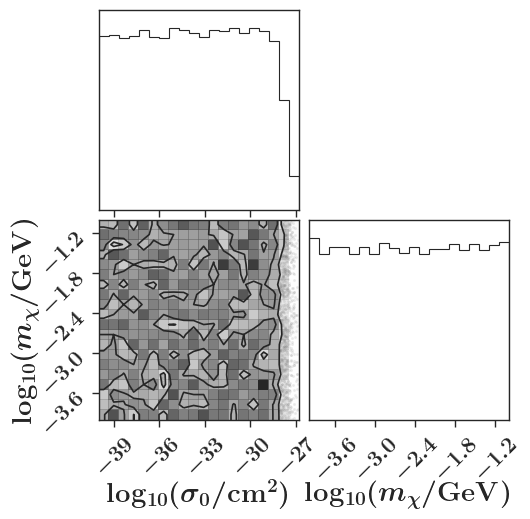

In [17]:
with open('pickled/mcmc_0.001_16_20000_2024-08-15_01-25-20.pkl', 'rb') as f:
    mcmc_output_edd = pickle.load(f)
print(mcmc_output_edd.shape)

labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_edd, labels=labels, dpi=450, levels=[0.68, 0.95]
);

(21328, 2)


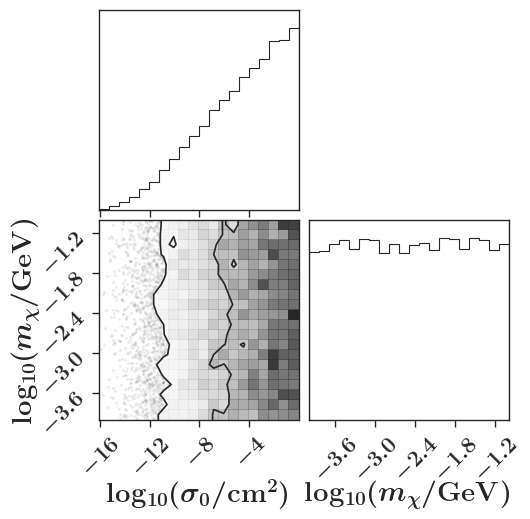

In [18]:
with open('pickled/mcmc_0.001_16_20000_eddington_0.1_2024-06-12_16-24-35.pkl', 'rb') as f:
    mcmc_output_edd_01 = pickle.load(f)
print(mcmc_output_edd_01.shape)

labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_edd_01, labels=labels, dpi=450, levels=[0.68, 0.95]
);

(21328, 2)


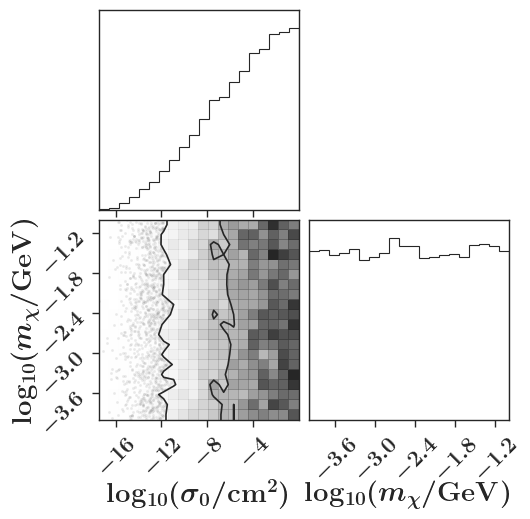

In [40]:
with open('pickled/mcmc_0.001_16_20000_eddington_0.01_2024-06-12_18-36-52.pkl', 'rb') as f:
    mcmc_output_edd_001 = pickle.load(f)
print(mcmc_output_edd_001.shape)

labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_edd_001, labels=labels, dpi=450, levels=[0.68, 0.95]
);

(21328, 2)


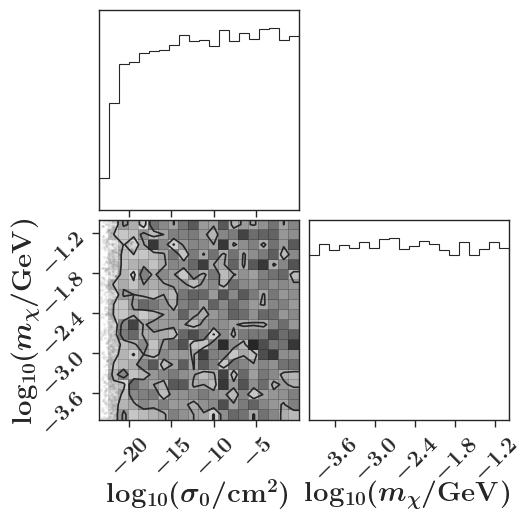

In [42]:


with open('pickled/mcmc_0.001_16_20000_2024-06-12_18-53-01.pkl', 'rb') as f:
    mcmc_output_iq_1 = pickle.load(f)
print(mcmc_output_iq_1.shape)

labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_iq_1, labels=labels, dpi=450, levels=[0.68, 0.95]
);


(21328, 2)


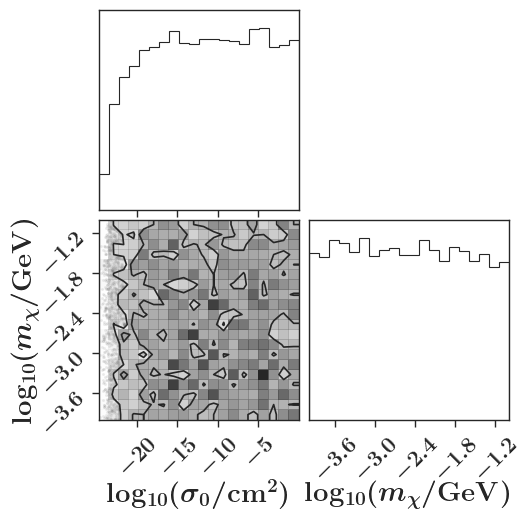

In [45]:

with open('pickled/mcmc_0.001_16_20000_2024-06-12_16-37-35.pkl', 'rb') as f:
    mcmc_output_iq_2 = pickle.load(f)
print(mcmc_output_iq_2.shape)

labels = [r"$\mathrm{log_{10}} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log_{10}} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
    mcmc_output_iq_2, labels=labels, dpi=450, levels=[0.68, 0.95]
);


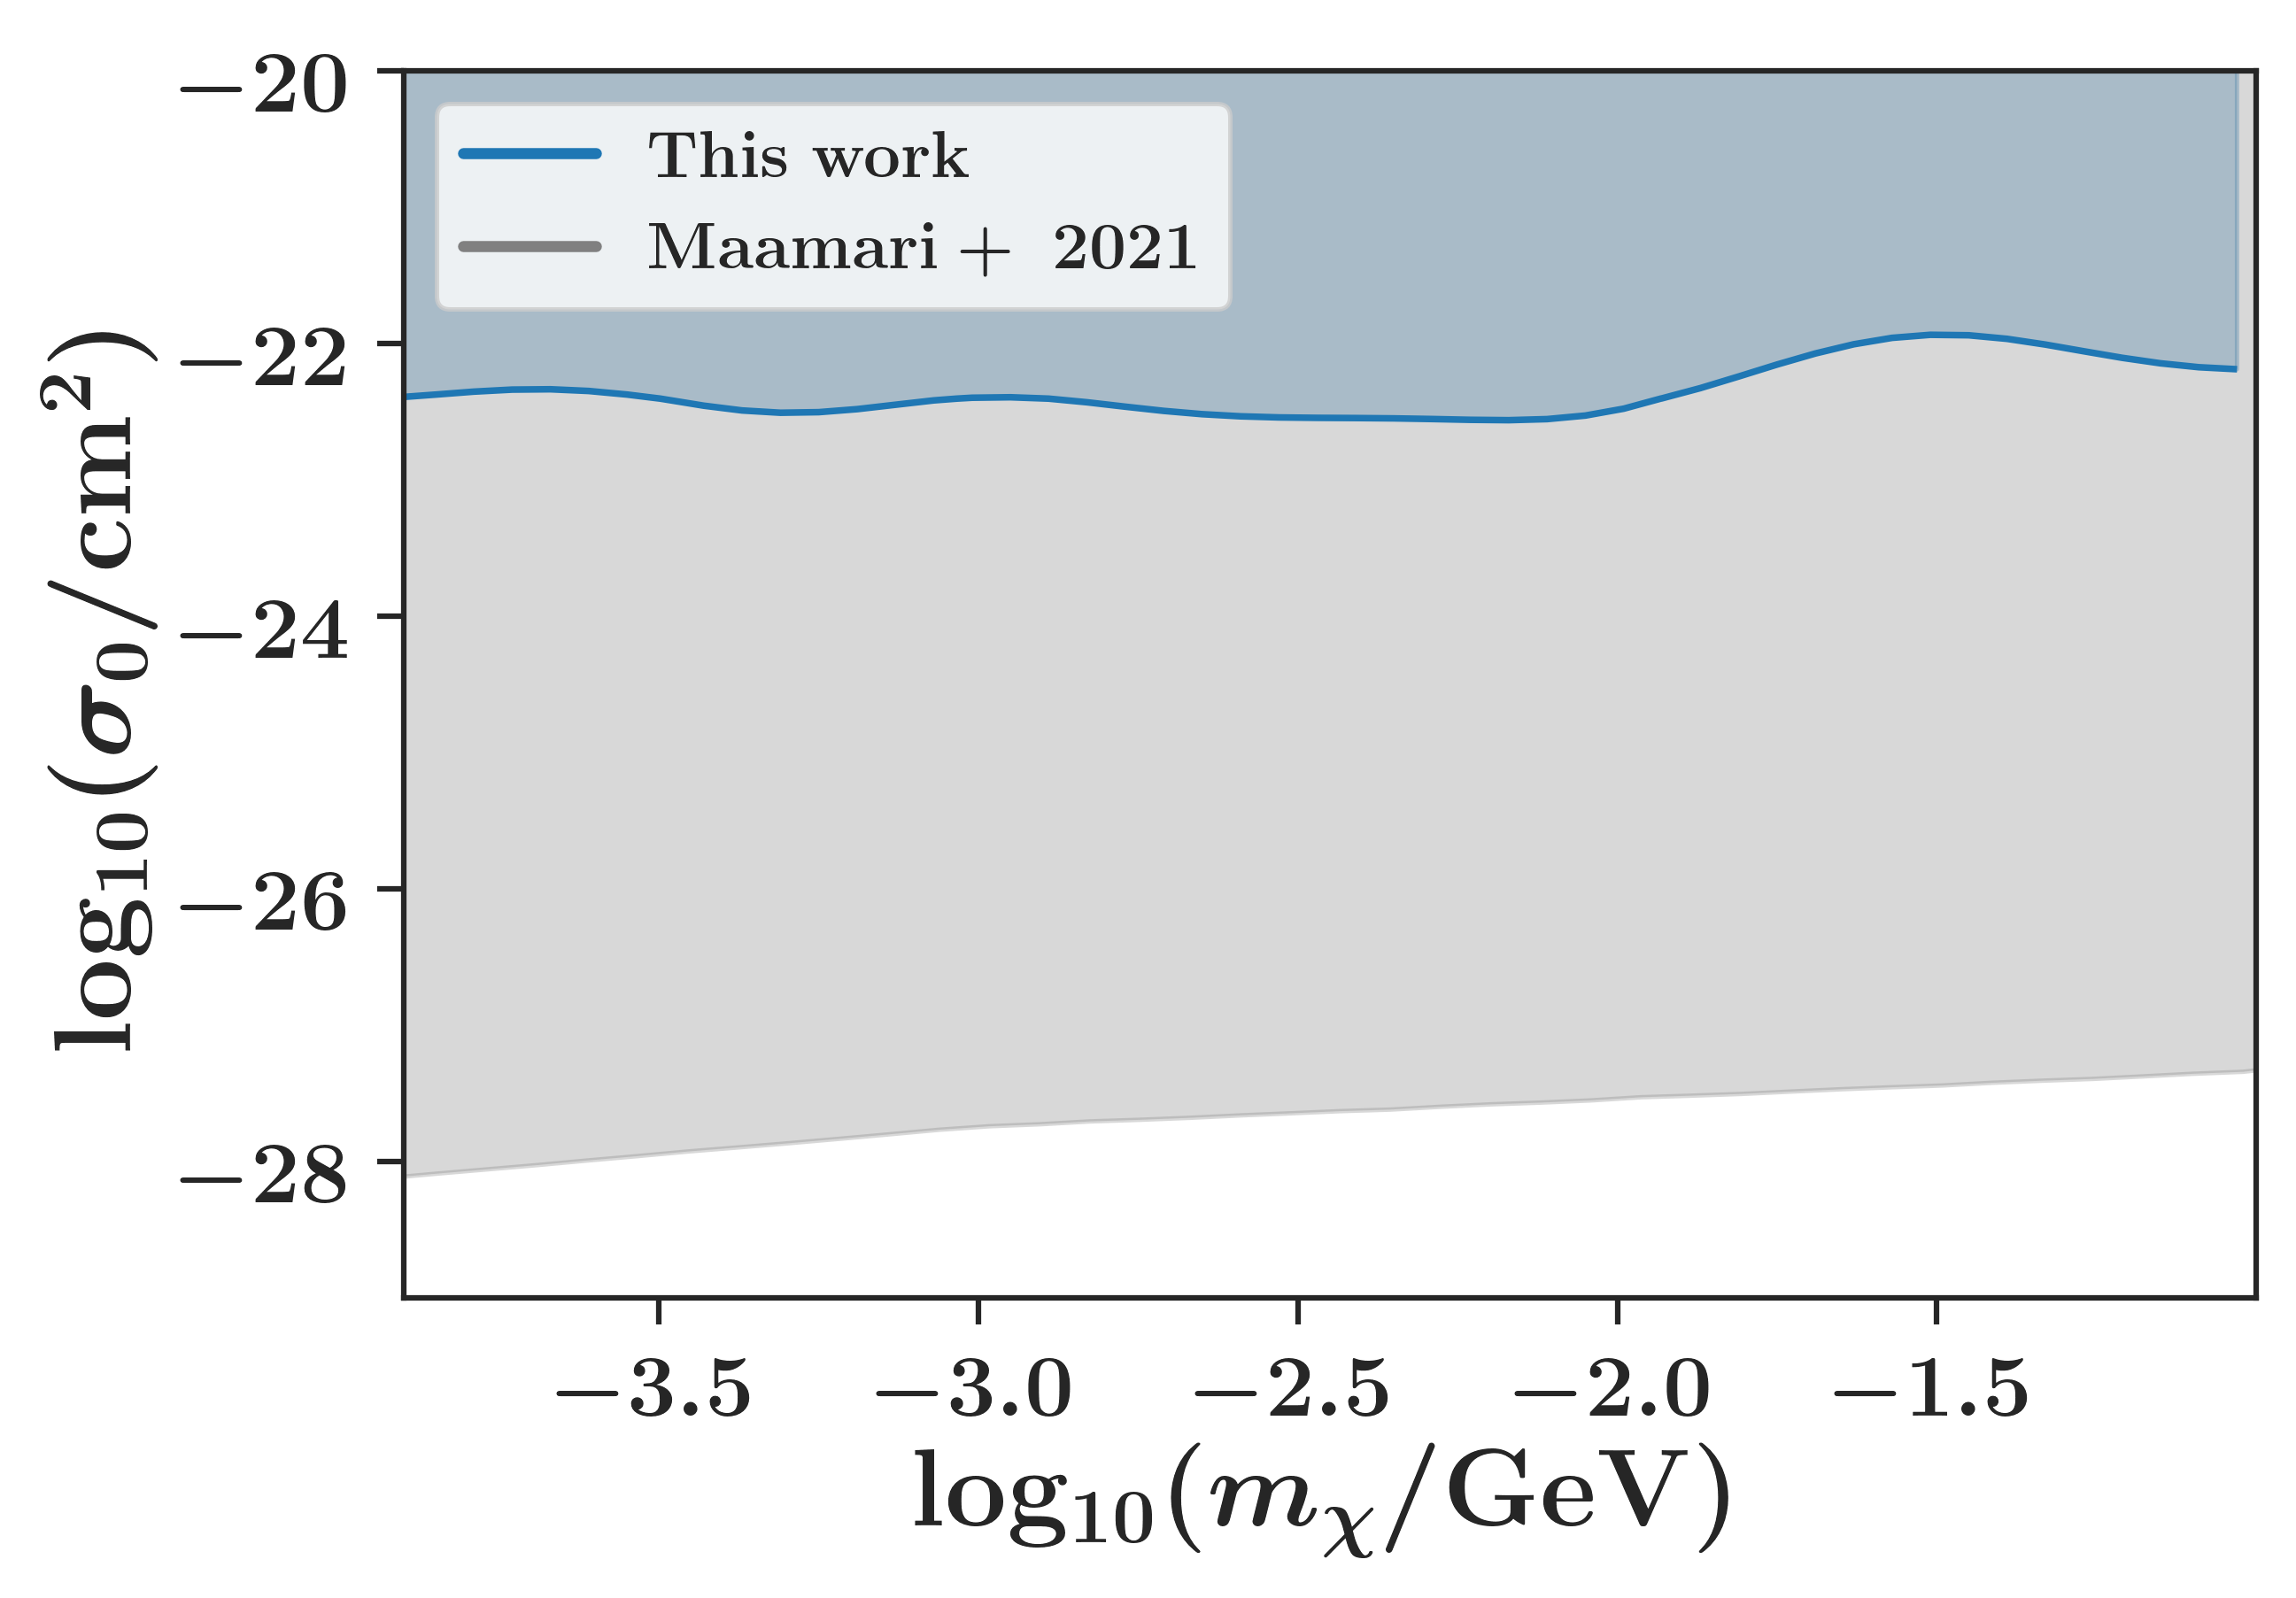

In [70]:
make_contour(mcmc_output_iq_1, -29, -20)

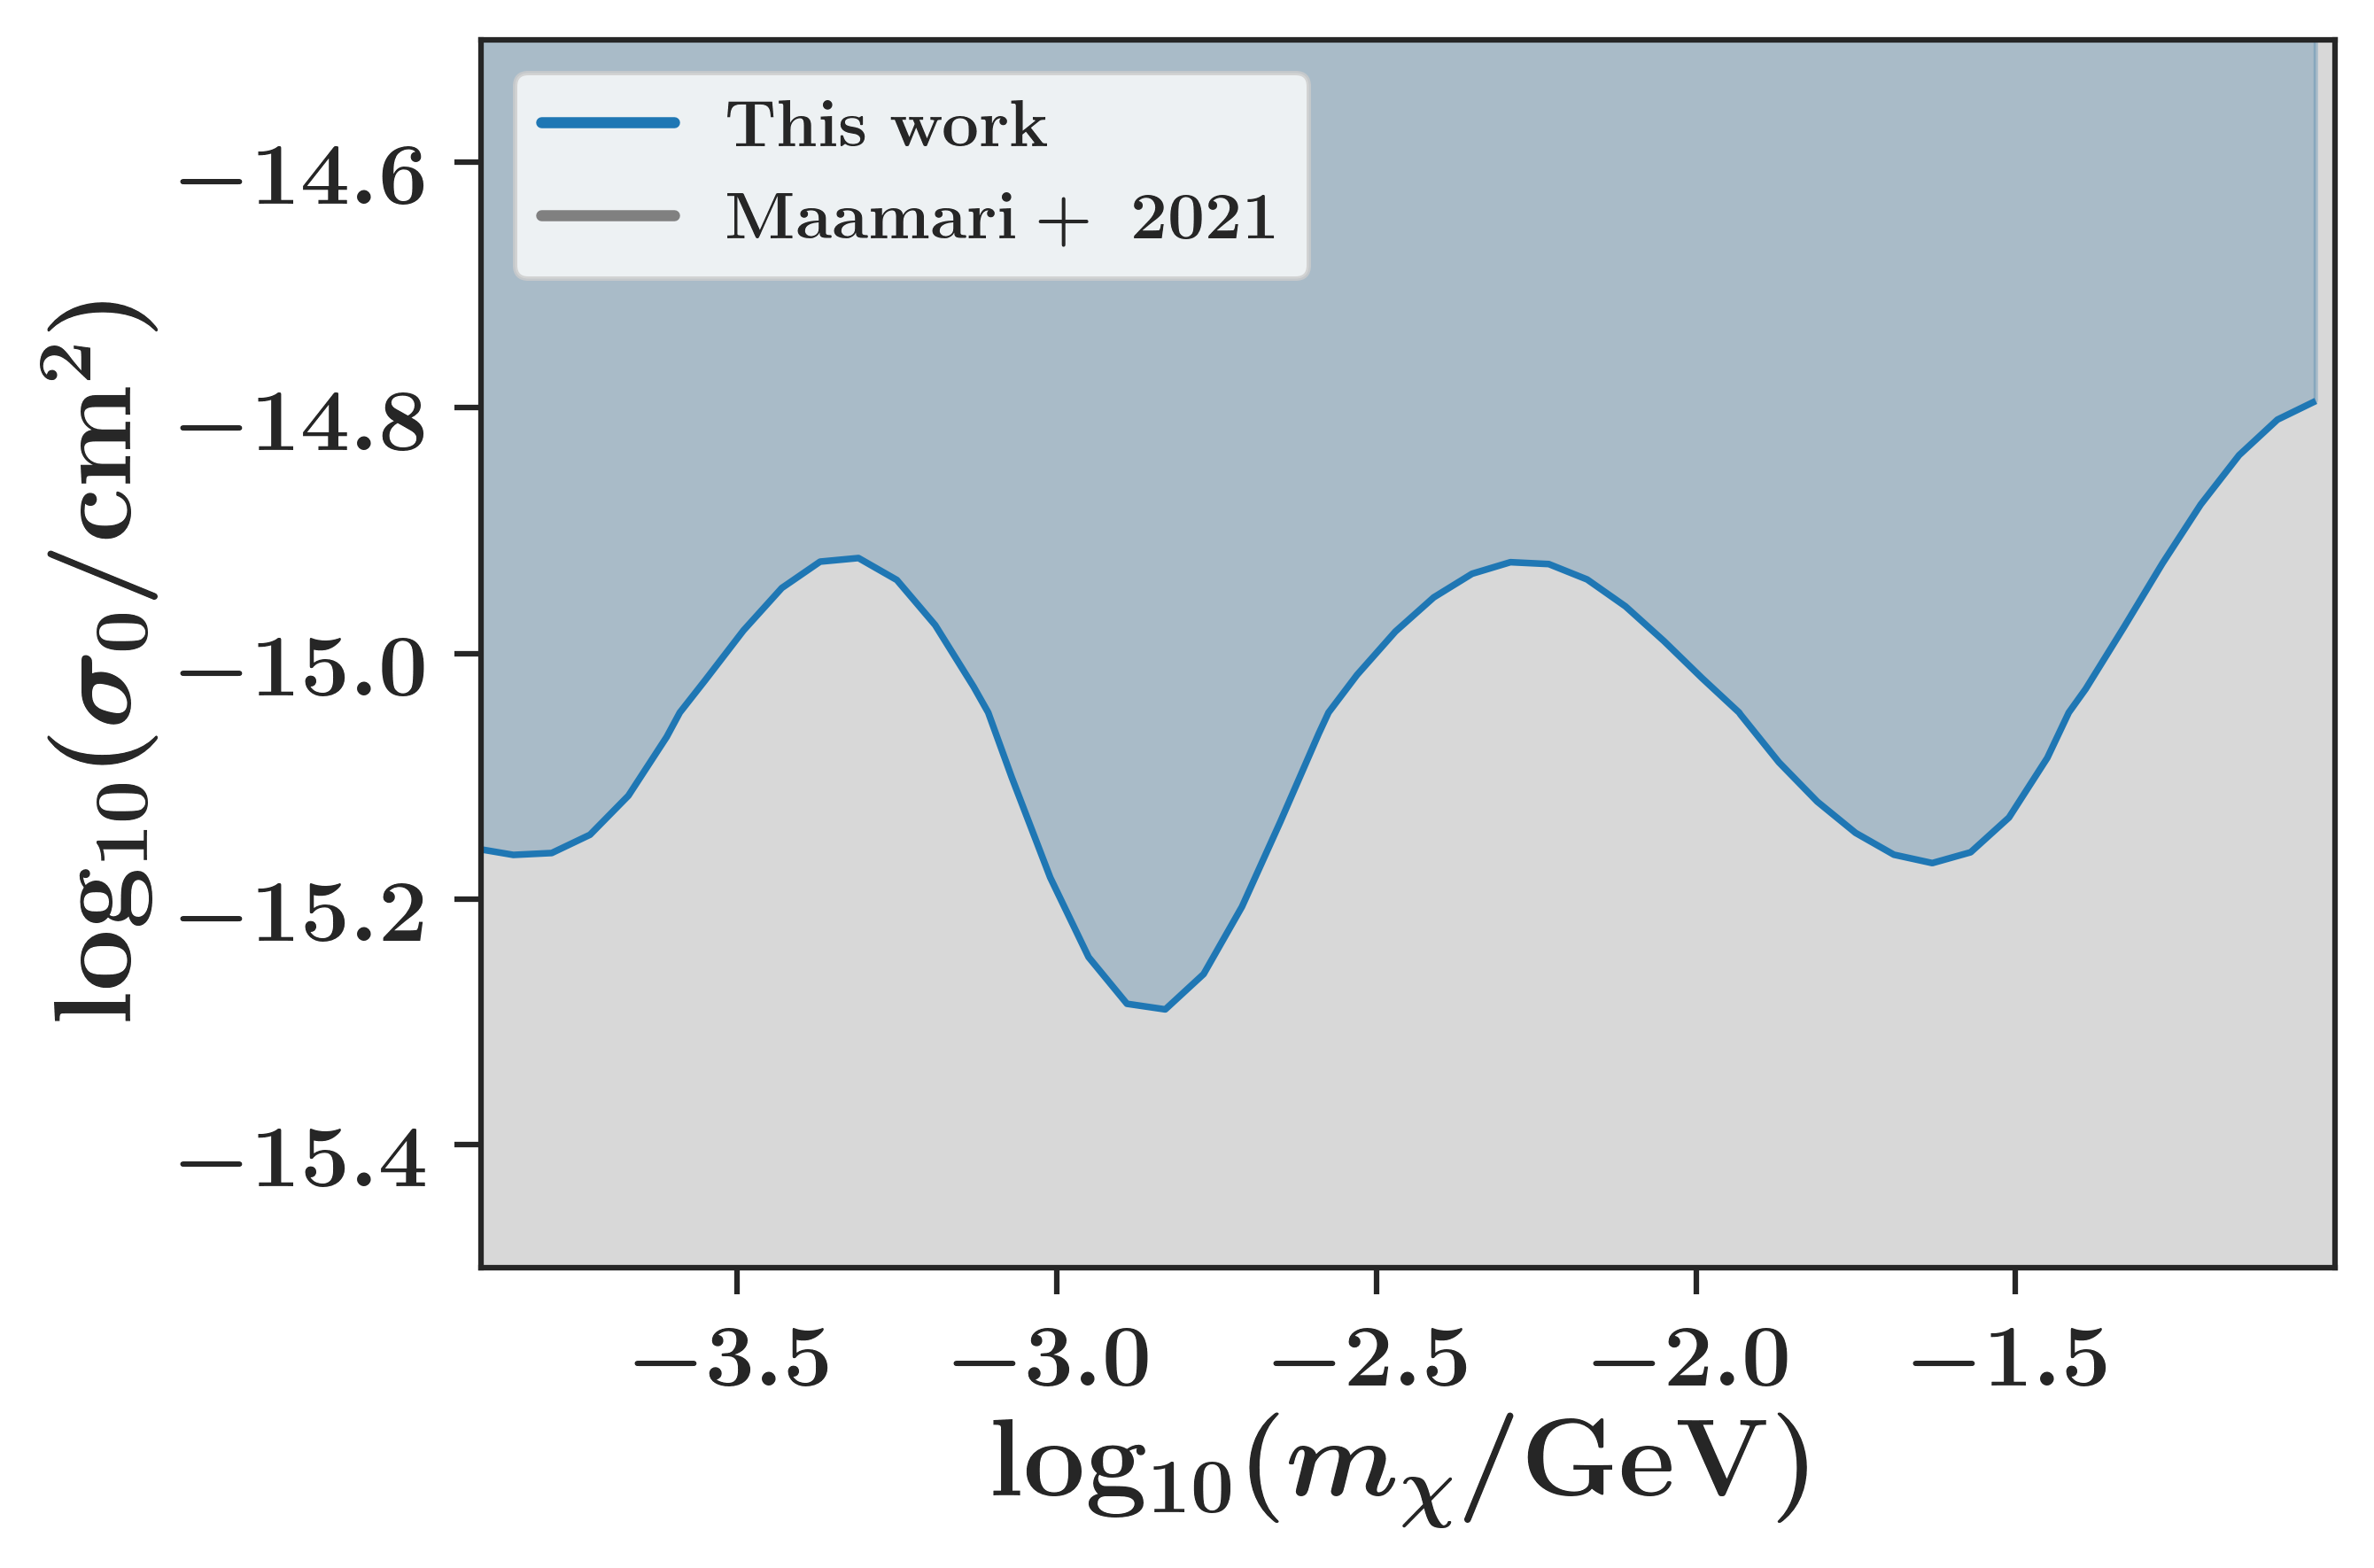

In [66]:
from make_contour_plot import make_contour

make_contour(mcmc_output_edd, -15.5, -14.5)



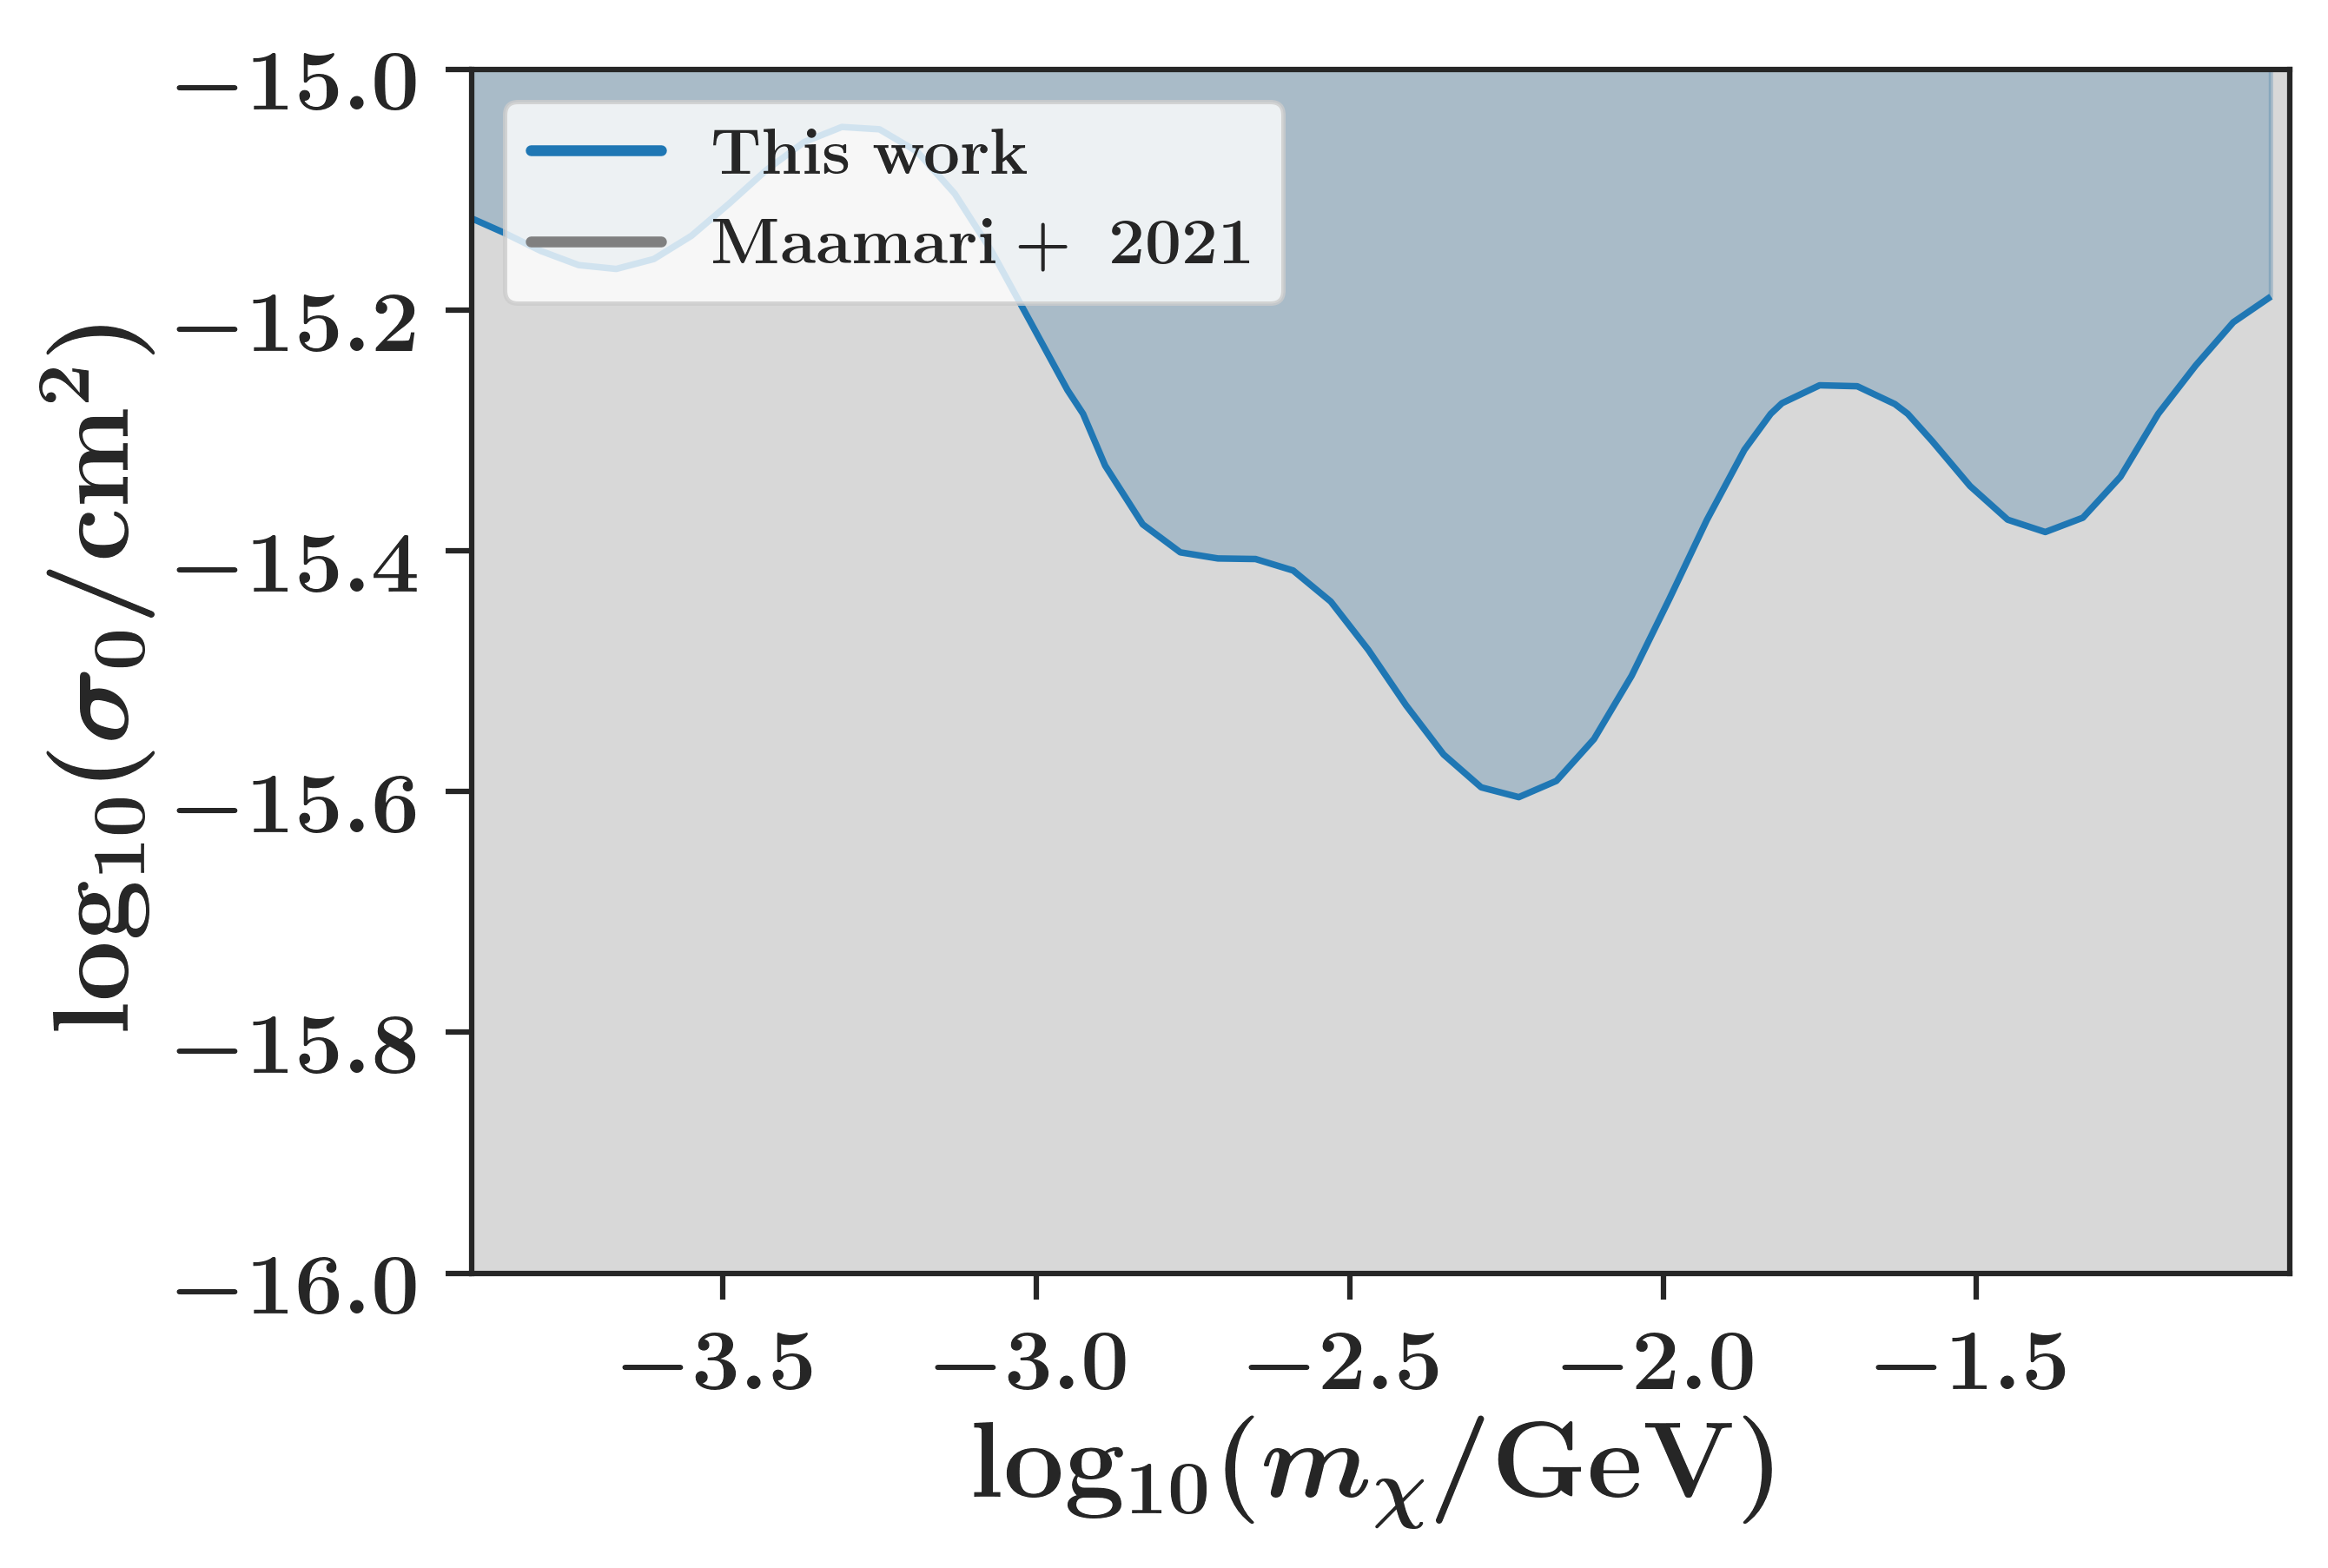

In [61]:
make_contour(mcmc_output_edd_01, -16, -15)

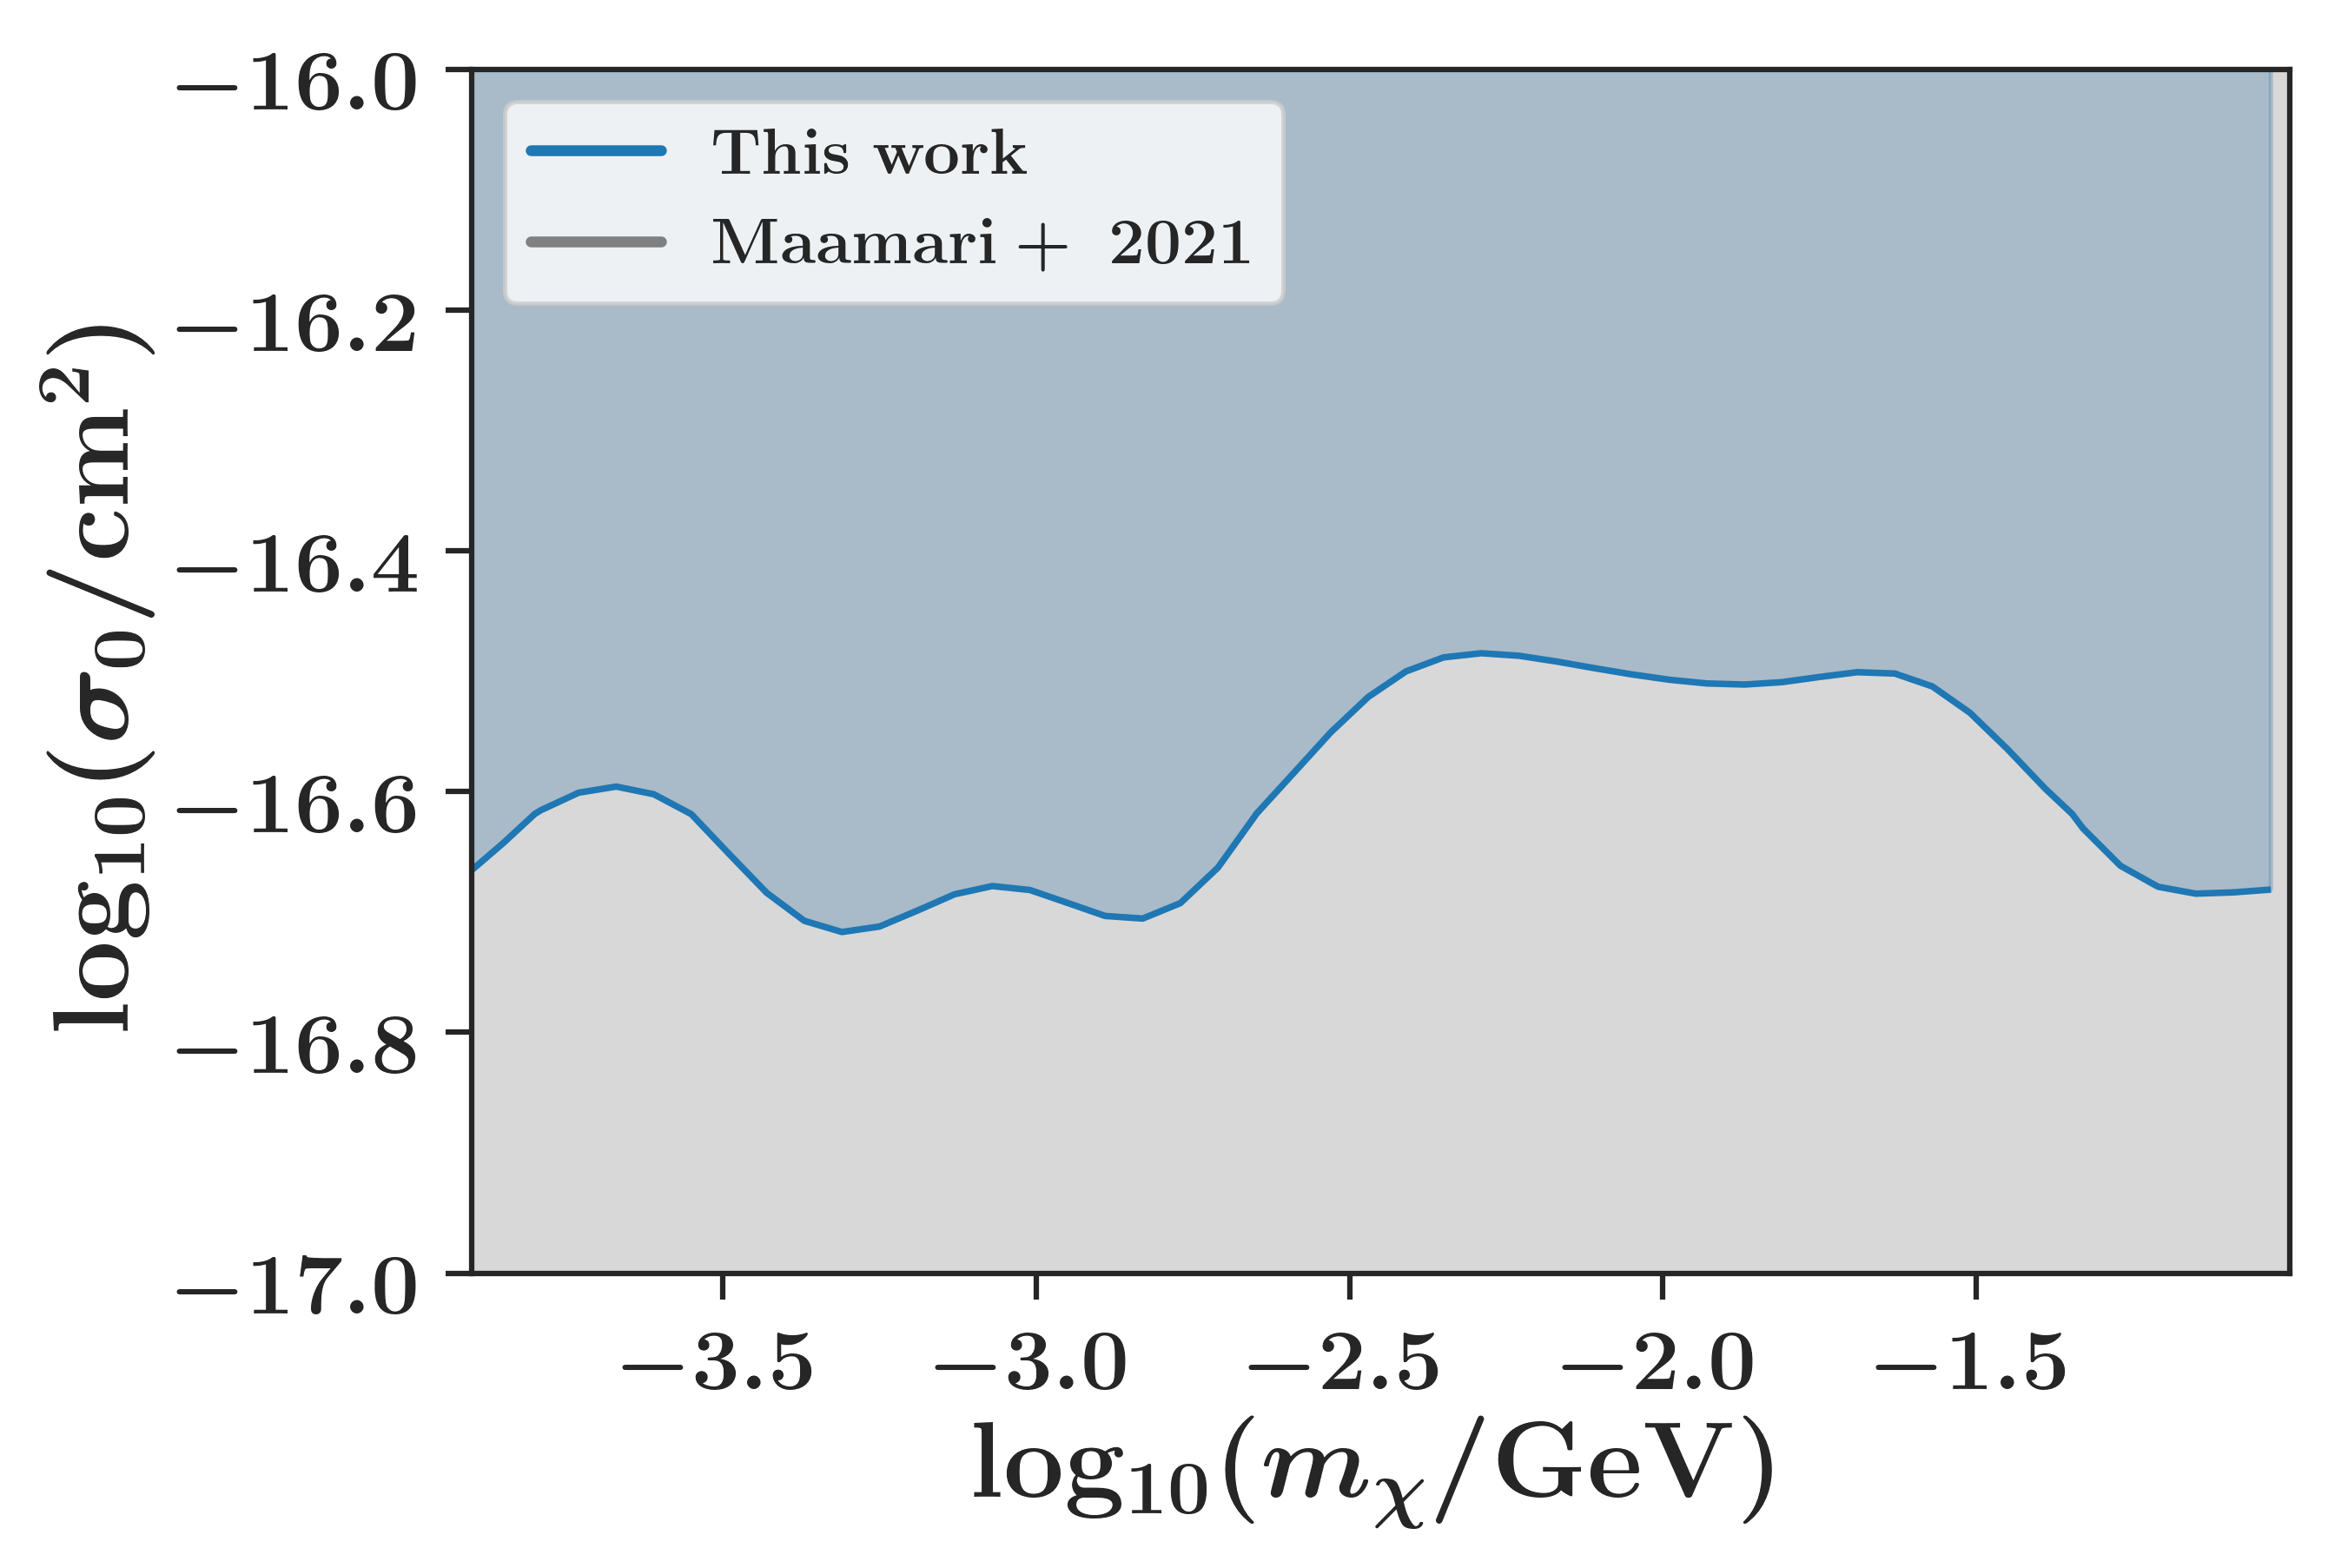

In [62]:
make_contour(mcmc_output_edd_001, -17, -16)